# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the tuned hyperparameters in `ARCH_HYPERPARAMS["resnet18_scratch"]`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: Waterval
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']


## Data loaders and class weights

In [2]:
cfg = ARCH_HYPERPARAMS["resnet18_scratch"]

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 24)
Train: 709 | Val: 170 | Test: 864


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 3.42e-04 | train loss 1.1537 acc 0.395 | val loss 1.1170 acc 0.459 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 3.42e-04 | train loss 1.0873 acc 0.536 | val loss 0.9889 acc 0.676 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 3.42e-04 | train loss 1.0965 acc 0.508 | val loss 1.0891 acc 0.465


[ResNet-18 (scratch)] Epoch   4/100 | LR: 3.42e-04 | train loss 1.0953 acc 0.432 | val loss 1.1055 acc 0.541


...

[ResNet-18 (scratch)] Epoch  19/100 | LR: 3.42e-04 | train loss 0.8725 acc 0.653 | val loss 0.7297 acc 0.641


[ResNet-18 (scratch)] Epoch  20/100 | LR: 3.42e-04 | train loss 0.8815 acc 0.629 | val loss 0.7771 acc 0.600


[ResNet-18 (scratch)] Epoch  21/100 | LR: 3.42e-04 | train loss 0.8689 acc 0.638 | val loss 0.9067 acc 0.524


[ResNet-18 (scratch)] Epoch  22/100 | LR: 3.42e-04 | train loss 0.8357 acc 0.659 | val loss 0.7143 acc 0.594


[ResNet-18 (scratch)] Epoch  23/100 | LR: 3.42e-04 | train loss 0.8238 acc 0.666 | val loss 0.8017 acc 0.618

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 23.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.6780)


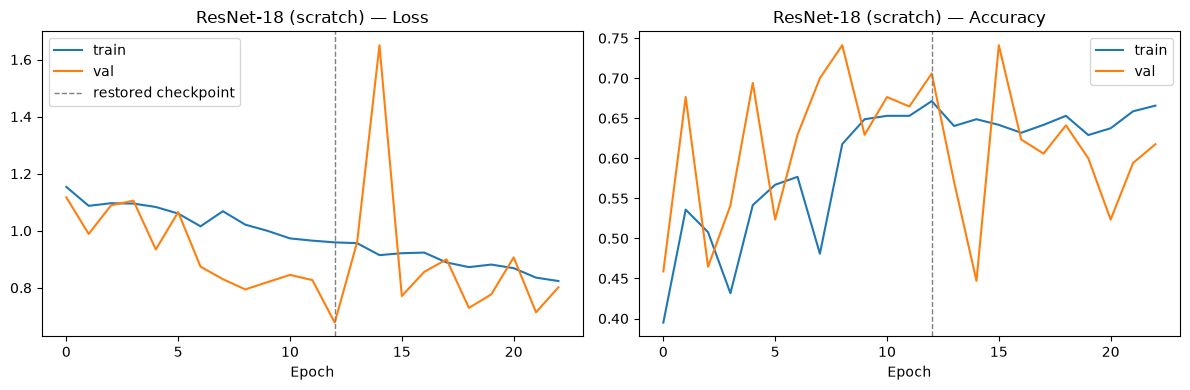

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.472


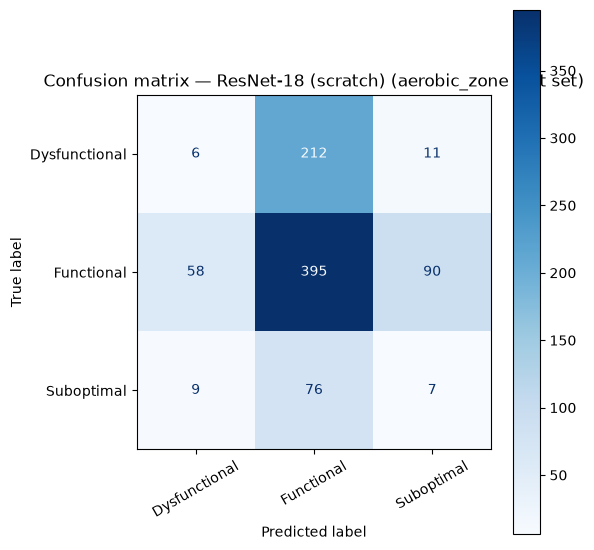

               precision    recall  f1-score   support

Dysfunctional      0.082     0.026     0.040       229
   Functional      0.578     0.727     0.644       543
   Suboptimal      0.065     0.076     0.070        92

     accuracy                          0.472       864
    macro avg      0.242     0.277     0.251       864
 weighted avg      0.392     0.472     0.423       864



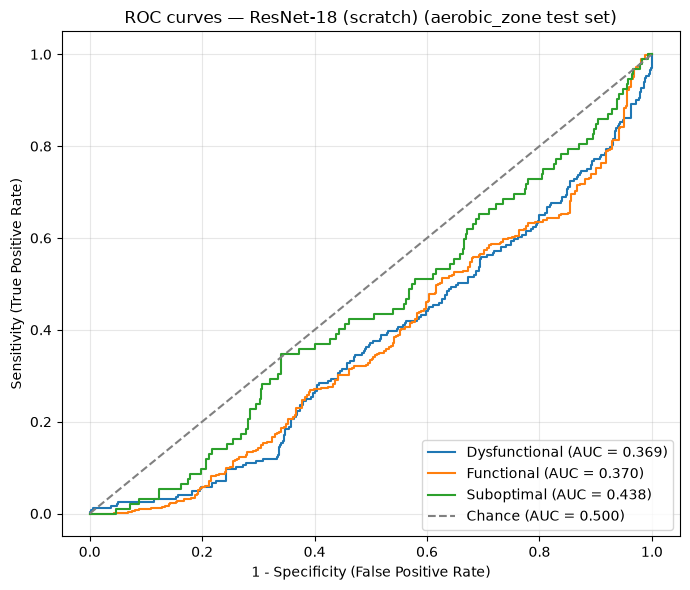

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.369
  Functional     : 0.370
  Suboptimal     : 0.438

Mean AUC (over 3/3 classes with test examples): 0.392


(np.float64(0.4722222222222222),
 {'Dysfunctional': 0.3685451982257676,
  'Functional': 0.369867414789189,
  'Suboptimal': 0.43783791394458205})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_Waterval.pkl
Saved model weights to ../models/pad/aerobic_zone_aug/aerobic_zone_resnet18_scratch_Waterval.pt
